In [1]:
import pandas as pd
df = pd.read_csv("penguins.csv")
print(df.shape)
print(df.isna().sum)
print(df["species"].value_counts())

(344, 8)
<bound method DataFrame.sum of      species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0      False   False           False          False              False   
1      False   False           False          False              False   
2      False   False           False          False              False   
3      False   False            True           True               True   
4      False   False           False          False              False   
..       ...     ...             ...            ...                ...   
339    False   False           False          False              False   
340    False   False           False          False              False   
341    False   False           False          False              False   
342    False   False           False          False              False   
343    False   False           False          False              False   

     body_mass_g    sex   year  
0          False  False  False  
1    

#Prompt log:You are helping with exploratory data analysis.
#My CSV has columns species,  island,  bill_length_mm,  bill_depth_mm, flipper_length_mm, body_mass_g,    sex, year,
#Write Python using pandas summarize missing data, compare flipper_length_mm across species, produce one labeled chart.
#Explain each step in comments.

Dataset shape: (344, 8)

Column data types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

Missing Data Summary:
                   Missing Count  Missing Percentage (%)
sex                           11                    3.20
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
bill_length_mm                 2                    0.58
body_mass_g                    2                    0.58
island                         0                    0.00
species                        0                    0.00
year                           0                    0.00

Flipper Length Summary by Species:
           Count  Mean (mm)  Median (mm)  Std Dev (mm)  Minimum (mm)  \
species                                                           

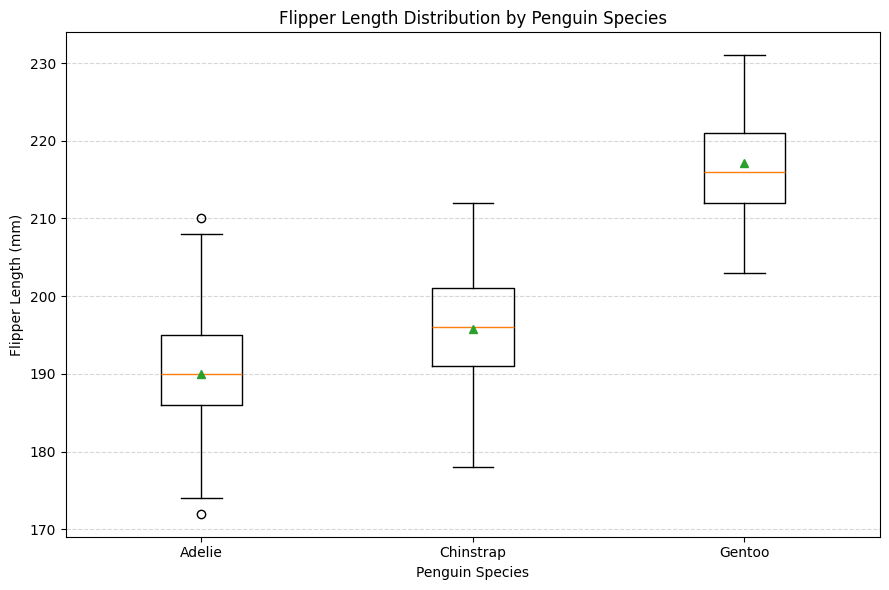

In [2]:

# Import pandas for working with tabular data.
import pandas as pd

# Import matplotlib for creating the chart.
import matplotlib.pyplot as plt

# --------------------------------------------------
# Step 1: Load the CSV file
# --------------------------------------------------

# Read the penguins dataset into a pandas DataFrame.
df = pd.read_csv("penguins.csv")

# Display the number of rows and columns and check column data types.
print("Dataset shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)


# --------------------------------------------------
# Step 2: Summarize missing data
# --------------------------------------------------

# Count missing values in each column.
missing_count = df.isna().sum()

# Calculate the percentage of missing values in each column.
missing_percent = (df.isna().mean() * 100).round(2)

# Combine counts and percentages into a readable summary table.
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percent
})

# Display columns with missing values first.
missing_summary = missing_summary.sort_values(
    by="Missing Count", ascending=False
)

print("\nMissing Data Summary:")
print(missing_summary)


# --------------------------------------------------
# Step 3: Compare flipper length across species
# --------------------------------------------------

# Remove rows where species or flipper length is missing.
# These values are needed for a valid species comparison.
flipper_data = df.dropna(
    subset=["species", "flipper_length_mm"]
).copy()

# Calculate descriptive statistics for each species.
# Count shows sample size; mean and median show typical length.
# Standard deviation measures variability; min and max show range.
species_summary = (
    flipper_data.groupby("species")["flipper_length_mm"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# Rename the columns to make the output easier to interpret.
species_summary.columns = [
    "Count",
    "Mean (mm)",
    "Median (mm)",
    "Std Dev (mm)",
    "Minimum (mm)",
    "Maximum (mm)"
]

print("\nFlipper Length Summary by Species:")
print(species_summary)


# --------------------------------------------------
# Step 4: Create one labeled chart
# --------------------------------------------------

# Group the flipper measurements by species.
# Each group will become a separate box in the chart.
species = sorted(flipper_data["species"].unique())

flipper_by_species = [
    flipper_data.loc[
        flipper_data["species"] == name, "flipper_length_mm"
    ]
    for name in species
]

# Create a box plot to compare distributions.
fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    flipper_by_species,
    tick_labels=species,
    showmeans=True
)

# Add a descriptive title and axis labels, including units.
ax.set_title("Flipper Length Distribution by Penguin Species")
ax.set_xlabel("Penguin Species")
ax.set_ylabel("Flipper Length (mm)")

# Add a light horizontal grid to make lengths easier to compare.
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Adjust spacing and display the chart.
plt.tight_layout()
plt.show()


In [3]:
df.groupby("species")["flipper_length_mm"].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


The means are the same for both of them.

Dataset shape: (344, 8)

Missing Data Summary:
                   Missing Count  Missing Percentage (%)
sex                           11                    3.20
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
bill_length_mm                 2                    0.58
body_mass_g                    2                    0.58
island                         0                    0.00
species                        0                    0.00
year                           0                    0.00

Flipper Length by Species and Island:
                     Count  Mean (mm)  Median (mm)  Std Dev (mm)  \
species   island                                                   
Adelie    Biscoe        44     188.80        189.5          6.73   
          Dream         56     189.73        190.0          6.59   
          Torgersen     51     191.20        191.0          6.23   
Chinstrap Dream         68     195.82        196.0          7

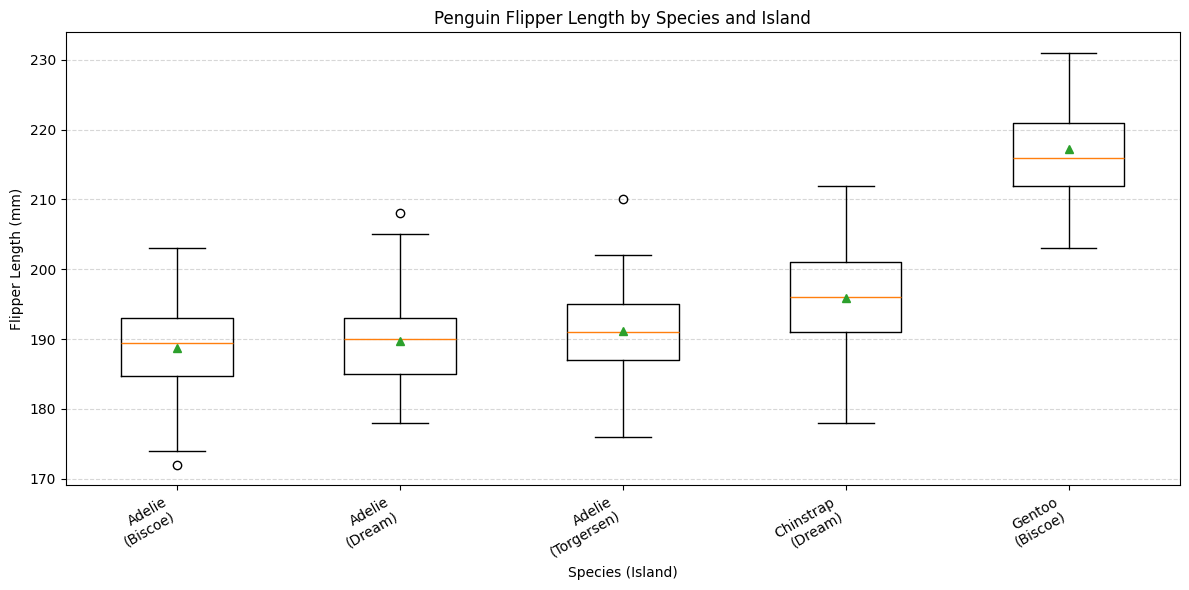

In [4]:

# Import pandas for data analysis and matplotlib for plotting.
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Step 1: Load the dataset
# --------------------------------------------------

# Read the CSV file into a DataFrame.
df = pd.read_csv("penguins.csv")

# Display the dataset dimensions.
print("Dataset shape:", df.shape)


# --------------------------------------------------
# Step 2: Summarize missing data
# --------------------------------------------------

# Count missing values in each column.
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (df.isna().mean() * 100).round(2)
})

# Display the missing-data summary.
print("\nMissing Data Summary:")
print(missing_summary.sort_values(
    by="Missing Count", ascending=False
))


# --------------------------------------------------
# Step 3: Prepare data for grouped analysis
# --------------------------------------------------

# Keep rows with known species, island, and flipper length.
# This ensures every observation can be assigned to a group.
analysis_df = df.dropna(
    subset=["species", "island", "flipper_length_mm"]
).copy()


# --------------------------------------------------
# Step 4: Compare flipper length by species AND island
# --------------------------------------------------

# Group observations by two categorical variables:
# species identifies the penguin species,
# island identifies where the penguin was observed.
group_summary = (
    analysis_df.groupby(["species", "island"])["flipper_length_mm"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# Rename the columns for easier interpretation.
group_summary.columns = [
    "Count",
    "Mean (mm)",
    "Median (mm)",
    "Std Dev (mm)",
    "Minimum (mm)",
    "Maximum (mm)"
]

# Print the statistics for each species-island combination.
print("\nFlipper Length by Species and Island:")
print(group_summary)


# --------------------------------------------------
# Step 5: Produce one labeled grouped chart
# --------------------------------------------------

# Find all observed species-island combinations.
groups = (
    analysis_df[["species", "island"]]
    .drop_duplicates()
    .sort_values(["species", "island"])
)

# Collect flipper measurements for each combination.
boxplot_data = []
group_labels = []

for _, group in groups.iterrows():
    # Select measurements matching this species and island.
    values = analysis_df.loc[
        (analysis_df["species"] == group["species"]) &
        (analysis_df["island"] == group["island"]),
        "flipper_length_mm"
    ]

    # Add the measurements and a descriptive axis label.
    boxplot_data.append(values)
    group_labels.append(
        f'{group["species"]}\n({group["island"]})'
    )

# Create a single figure containing all groups.
fig, ax = plt.subplots(figsize=(12, 6))

# Draw one box for each species-island combination.
ax.boxplot(
    boxplot_data,
    tick_labels=group_labels,
    showmeans=True
)

# Add a clear title and labeled axes with units.
ax.set_title("Penguin Flipper Length by Species and Island")
ax.set_xlabel("Species (Island)")
ax.set_ylabel("Flipper Length (mm)")

# Improve readability with a horizontal reference grid.
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Rotate labels if necessary and prevent clipping.
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Display the chart.
plt.show()


I would use the change it made. I asked it to add an extra grouping. Instead of doing it by species only it does it by island as well.

Step 7: How different is the body mass depending on the sex and how is the gap between species?

species    sex   
Adelie     female    3369.0
           male      4043.0
Chinstrap  female    3527.0
           male      3939.0
Gentoo     female    4680.0
           male      5485.0
Name: body_mass_g, dtype: float64


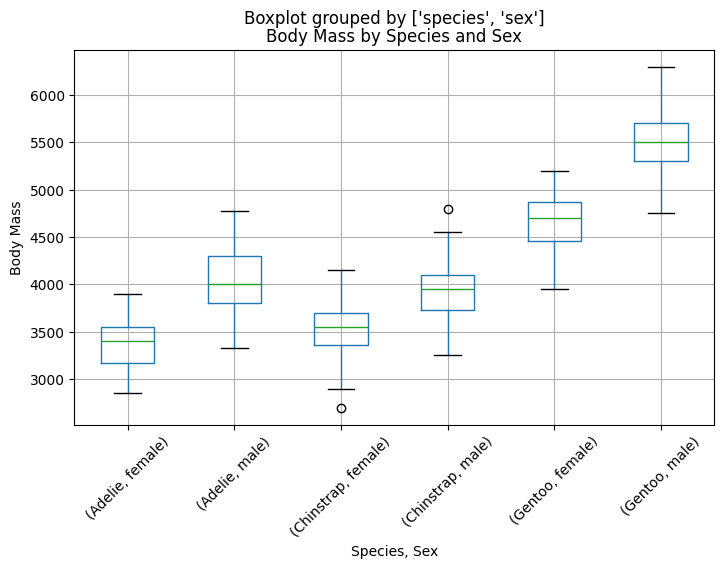

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

print(df.groupby(["species", "sex"])["body_mass_g"].mean().round(0))

df.boxplot(column="body_mass_g", by=["species", "sex"], figsize=(8, 5), rot=45)
plt.title("Body Mass by Species and Sex")
plt.ylabel("Body Mass")
plt.xlabel("Species, Sex")
plt.show()

Step 8: I would not use anything that has private information. Something that has infomration that should not be scanned by AI. Like financial information, personal health, or anything work related. I would use an approved internal tool if I have to use AI.